# Milestone 2: Object detection with YOLOv8 on multi-object grid images (73 objects)

**Goal.** Train YOLOv8 to find every object in an image that contains many objects, and report each object's ID and location.

**Data.** All 73 objects in the shared sheet (38 from Section 01 and 35 from Section 03), 6,941 photos at 224x224 from the Milestone 1 dataset. The Milestone 1 train, validation and test split is reused, so no source photo can appear in more than one split.

**Labels.** The shared dataset has object IDs but no bounding boxes, so boxes are generated by two open-vocabulary detectors (YOLO-World and Grounding DINO) and fused. The Section 01 objects were labelled first, with the same detectors, and their 3,048 boxes are read from `labels.csv`. This notebook labels the 35 Section 03 objects and concatenates the two sets.

**Order:** top to bottom on a T4 GPU. Step 3 and Step 7 are the long ones. Both save to Drive so a disconnect does not cost the work.


## Step 1: Setup

In [ ]:
!pip -q install ultralytics

import os, io, json, re, random, shutil, zipfile, gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps, ImageEnhance
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")

assert torch.cuda.is_available(), "Runtime > Change runtime type > T4 GPU"

M1_DIR = Path("/content/drive/MyDrive/IE7615_pytorch")
M2_DIR = Path("/content/drive/MyDrive/IE7615_detection")
DATA = Path("/content/data")
M2_DIR.mkdir(exist_ok=True)
if not (DATA / "manifests").exists():
    DATA.mkdir(exist_ok=True)
    zipfile.ZipFile(M1_DIR / "dataset_224.zip").extractall(DATA)

Mounted at /content/drive


In [ ]:
NAMES = {
    "OBJ001": "Basketball",
    "OBJ002": "water bottle",
    "OBJ003": "NoteBook",
    "OBJ004": "Toy Car",
    "OBJ005": "Computer mouse",
    "OBJ006": "Capybara Toy",
    "OBJ007": "Apple",
    "OBJ008": "Cat",
    "OBJ009": "Marshall Speaker",
    "OBJ010": "Nike sneakers",
    "OBJ011": "mug",
    "OBJ012": "Computer Keyboard",
    "OBJ013": "Mobile phone",
    "OBJ014": "Sunglasses",
    "OBJ015": "Water Tumbler",
    "OBJ016": "Sandisk Portable SSD",
    "OBJ017": "Controller",
    "OBJ018": "Rubiks cube",
    "OBJ019": "Plant",
    "OBJ020": "Airpod",
    "OBJ021": "Toy Bunny",
    "OBJ022": "Guitar",
    "OBJ023": "Bracelet",
    "OBJ024": "Plush doll",
    "OBJ025": "Watch",
    "OBJ026": "Red Sox Cap",
    "OBJ027": "Tennis ball",
    "OBJ028": "banana",
    "OBJ029": "Orange",
    "OBJ030": "Tennis racket",
    "OBJ031": "UNO card box",
    "OBJ032": "Sound Card",
    "OBJ033": "Duck",
    "OBJ034": "Table Tennis Racket",
    "OBJ035": "Badminton racket",
    "OBJ036": "Pencil case",
    "OBJ037": "Candle",
    "OBJ038": "Perfume bottle",
    "OBJ039": "Scissors",
    "OBJ040": "Clutcher",
    "OBJ041": "Table fan",
    "OBJ042": "Mouth guard case",
    "OBJ043": "Swimming Goggels",
    "OBJ044": "Anime Figurine",
    "OBJ045": "Wayfarer Sunglasses",
    "OBJ046": "iWatch",
    "OBJ047": "Backpack",
    "OBJ048": "Wireless powerbank",
    "OBJ049": "Pickleball bat",
    "OBJ050": "Hairbrush",
    "OBJ051": "tissue",
    "OBJ052": "Spoon",
    "OBJ053": "Moisturizer",
    "OBJ054": "Purse",
    "OBJ055": "Scientific Calculator",
    "OBJ056": "Trader Joe's Bag",
    "OBJ057": "Power Bank",
    "OBJ058": "Footstool",
    "OBJ059": "Comb",
    "OBJ060": "Sleep Mask",
    "OBJ061": "Card wallet",
    "OBJ062": "Headphones",
    "OBJ063": "Measuring Bottle",
    "OBJ064": "RGB Projector",
    "OBJ065": "Analog watch",
    "OBJ066": "hair oil",
    "OBJ067": "Men's Wallet",
    "OBJ068": "Neck Pillow",
    "OBJ069": "knife",
    "OBJ070": "Astronaut projector",
    "OBJ071": "Sloth Plushie",
    "OBJ072": "Dog",
    "OBJ073": "Bowl",
}

print(len(NAMES), "objects from the shared sheet (Section 01 + Section 03)")

73 objects from the shared sheet (Section 01 + Section 03)


## Step 2: Select the photos for all 73 objects

Reads the Milestone 1 split files (train, val, test) and keeps the photos of the 73 objects. `OBJ054_017` is excluded because it is not a photo of the object.

If any of the 73 has no photos in `dataset_224.zip`, this is reported before the long steps start instead of crashing in the middle of them.


In [ ]:
meta = pd.read_csv(M1_DIR / "metadata.csv")
bad = set(meta.loc[meta["name"].str.upper().str.startswith("OBJ054_017"), "processed_path"])

parts = []
for split in ["train", "val", "test"]:
    df = pd.read_csv(DATA / "manifests" / f"{split}.csv")
    df = df[df.label.isin(NAMES) & ~df.filepath.isin(bad)].copy()
    df["split"] = split
    parts.append(df)
photos = pd.concat(parts, ignore_index=True)

missing_ids = sorted(set(NAMES) - set(photos.label))
print("Object IDs:", photos.label.nunique(), "of 73 | photos:", len(photos), "| excluded OBJ054_017:", len(bad))
print(photos.groupby("split").size().to_dict())
if missing_ids:
    print("\nNO PHOTOS in dataset_224.zip for:", missing_ids)
    print("Get these from the team, or they cannot be trained.")
else:
    print("\nAll 73 objects have photos.")

Object IDs: 73 of 73 | photos: 6941 | excluded OBJ054_017: 1
{'test': 1081, 'train': 4832, 'val': 1028}

All 73 objects have photos.


## Step 3: Label the objects that do not have boxes yet

Only the objects missing from `labels.csv` (the 35 Section 03 objects) go through the detectors. Both detectors get the object's name as a text prompt and the highest-scoring box is kept: YOLO-World with a confidence cutoff of 0.001, and Grounding DINO with box and text thresholds of 0.2. Raw detections are written to Drive before fusion.

`USE_YOLOWORLD = False` runs Grounding DINO alone, which roughly halves this step.


In [ ]:
USE_YOLOWORLD = True

old = pd.read_csv(M2_DIR / "labels.csv")
done = set(old.label.unique())
todo = photos[~photos.label.isin(done)].copy()
print(f"already labelled: {len(done)} objects, {len(old)} photos")
print(f"to label now:     {todo.label.nunique()} objects, {len(todo)} photos")
print(sorted(todo.label.unique()))

already labelled: 38 objects, 3048 photos
to label now:     35 objects, 3336 photos
['OBJ002', 'OBJ005', 'OBJ006', 'OBJ007', 'OBJ008', 'OBJ009', 'OBJ010', 'OBJ013', 'OBJ014', 'OBJ016', 'OBJ017', 'OBJ018', 'OBJ023', 'OBJ024', 'OBJ025', 'OBJ026', 'OBJ028', 'OBJ029', 'OBJ033', 'OBJ044', 'OBJ047', 'OBJ049', 'OBJ050', 'OBJ051', 'OBJ053', 'OBJ056', 'OBJ058', 'OBJ059', 'OBJ061', 'OBJ067', 'OBJ068', 'OBJ069', 'OBJ070', 'OBJ071', 'OBJ072']


In [ ]:
from ultralytics import YOLOWorld
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

def run_yoloworld(photos, conf=0.001):
    model = YOLOWorld("yolov8l-worldv2.pt")
    out = {}
    for label, g in tqdm(photos.groupby("label"), desc="YOLO-World"):
        model.set_classes([NAMES[label]])
        fps = list(g.filepath)
        for i in range(0, len(fps), 32):
            chunk = fps[i:i + 32]
            res = model.predict([str(DATA / p) for p in chunk], conf=conf, imgsz=640, max_det=10, verbose=False)
            for fp, r in zip(chunk, res):
                if len(r.boxes):
                    j = int(r.boxes.conf.argmax())
                    out[fp] = (r.boxes.xyxy[j].tolist(), float(r.boxes.conf[j]))
    del model; gc.collect(); torch.cuda.empty_cache()
    return out

@torch.no_grad()
def run_gdino(photos, model_id="IDEA-Research/grounding-dino-base"):
    proc = AutoProcessor.from_pretrained(model_id)
    model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to("cuda").eval()
    out = {}
    for label, g in tqdm(photos.groupby("label"), desc="Grounding DINO"):
        text = NAMES[label].lower().strip() + "."
        fps = list(g.filepath)
        for i in range(0, len(fps), 2):
            chunk = fps[i:i + 2]
            imgs = [Image.open(DATA / p).convert("RGB") for p in chunk]
            inputs = proc(images=imgs, text=[text] * len(imgs), return_tensors="pt", padding=True).to("cuda")
            outputs = model(**inputs)
            sizes = [im.size[::-1] for im in imgs]
            try:
                res = proc.post_process_grounded_object_detection(outputs, inputs.input_ids, threshold=0.2,
                                                                  text_threshold=0.2, target_sizes=sizes)
            except TypeError:
                res = proc.post_process_grounded_object_detection(outputs, inputs.input_ids, box_threshold=0.2,
                                                                  text_threshold=0.2, target_sizes=sizes)
            for fp, r in zip(chunk, res):
                if len(r["boxes"]):
                    j = int(r["scores"].argmax())
                    out[fp] = (r["boxes"][j].tolist(), float(r["scores"][j]))
    del model; gc.collect(); torch.cuda.empty_cache()
    return out

A = run_yoloworld(todo) if USE_YOLOWORLD else {}
B = run_gdino(todo)
print(f"YOLO-World {len(A)}/{len(todo)} | Grounding DINO {len(B)}/{len(todo)}")
json.dump({"A": A, "B": B}, open(M2_DIR / "raw_detections_73new.json", "w"))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


YOLO-World:   0%|          | 0/35 [00:00<?, ?it/s]

requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 37 packages in 1.10s
Prepared 2 packages in 4.49s
Installed 2 packages in 2ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 6.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect




  0%|                                               | 0.00/338M [00:00<?, ?iB/s]
  1%|▍                                     | 3.38M/338M [00:00<00:09, 35.4MiB/s]
  7%|██▊                                    | 24.3M/338M [00:00<00:02, 143MiB/s]
 13%|█████                                  | 44.2M/338M [00:00<00:01, 173MiB/s]
 19%|███████▎                               | 63.6M/338M [00:00<00:01, 185MiB/s]
 24%|█████████▍                             | 81.8M/338M [00:00<00:01, 187MiB/s]
 30%|███████████▌                           | 99.6M/338M [00:00<00:01, 176MiB/s]
 35%|█████████████▊                          | 117M/338M [00:00<00:01, 165MiB/s]
 40%|███████████████▉                        | 135M/338M [00:00<00:01, 173MiB/s]
 45%|█████████████████▉                      | 151M/338M [00:00<00:01, 171MiB/s]
 50%|████████████████████▏                   | 170M/338M [00:01<00:00, 179MiB/s]
 56%|██████████████████████▏                 | 188M/338M [00:01<00:00, 176MiB/s]
 61%|██████████████████████

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  933MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

Grounding DINO:   0%|          | 0/35 [00:00<?, ?it/s]

YOLO-World 3002/3336 | Grounding DINO 3307/3336


### Agreement between the two labellers

For every photo, checks whether the two detectors' boxes overlap (IoU of at least 0.6). Objects at the bottom of this table are the ones to look at in Step 5.


In [ ]:
def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

todo["has_A"] = todo.filepath.isin(A)
todo["has_B"] = todo.filepath.isin(B)
todo["agree"] = [fp in A and fp in B and iou(A[fp][0], B[fp][0]) >= 0.6 for fp in todo.filepath]
print(f"agree (IoU >= 0.6): {todo.agree.mean():.1%}")
rate = todo.groupby("label")[["has_A", "has_B", "agree"]].mean().round(2)
rate.insert(0, "name", [NAMES[l] for l in rate.index])
print(rate.sort_values("agree").head(12))

agree (IoU >= 0.6): 70.2%
                       name  has_A  has_B  agree
label                                           
OBJ070  Astronaut projector   0.51   1.00   0.14
OBJ010        Nike sneakers   1.00   1.00   0.18
OBJ050            Hairbrush   0.63   0.91   0.23
OBJ049       Pickleball bat   0.42   1.00   0.36
OBJ006         Capybara Toy   0.44   1.00   0.43
OBJ068          Neck Pillow   0.96   1.00   0.46
OBJ025                Watch   0.94   0.98   0.48
OBJ033                 Duck   0.56   1.00   0.55
OBJ058            Footstool   0.99   1.00   0.55
OBJ051               tissue   1.00   1.00   0.57
OBJ061          Card wallet   0.92   1.00   0.58
OBJ053          Moisturizer   0.94   1.00   0.59


## Step 4: Fuse, apply the 20% drop cap, save `labels_73.csv`

Average the boxes when they agree at IoU 0.5 or more, take the more confident box when they disagree, use the single box when only one model found one, and drop photos with no box. Further weak (disagreeing) photos are dropped, lowest confidence first, but never more than 20% of any object's photos. The result is concatenated with the Section 01 labels.


In [ ]:
THR_IOU = 0.5
MAX_DROP = 0.20

def ok_box(b):
    return b is not None and (b[2] - b[0]) >= 4 and (b[3] - b[1]) >= 4

recs = []
for r in todo.itertuples():
    fp = r.filepath
    a = A.get(fp); b = B.get(fp)
    a = a[0] if a and ok_box(a[0]) else None
    b = b[0] if b and ok_box(b[0]) else None
    ca = A.get(fp, (None, 0.0))[1]
    cb = B.get(fp, (None, 0.0))[1]
    if a and b:
        v = iou(a, b)
        if v >= THR_IOU:
            box, status, score = [(a[i] + b[i]) / 2 for i in range(4)], "accept", v
        else:
            box, status, score = (a if ca >= cb else b), "disagree", max(ca, cb)
    elif a or b:
        box, status, score = (a or b), "single", max(ca, cb)
    else:
        box, status, score = None, "none", 0.0
    recs.append({"filepath": fp, "label": r.label, "split": r.split,
                 "status": status, "score": score,
                 "x1": box[0] if box else None, "y1": box[1] if box else None,
                 "x2": box[2] if box else None, "y2": box[3] if box else None})

new = pd.DataFrame(recs)
rank = {"accept": 0, "single": 1, "disagree": 2, "none": 3}
keep = []
for lab, g in new.groupby("label"):
    g = g.assign(_r=g.status.map(rank)).sort_values(["_r", "score"], ascending=[True, False])
    cap = int(len(g) * MAX_DROP)
    nones = g[g.status == "none"]
    extra = g[g.status == "disagree"].tail(max(0, cap - len(nones)))
    drop = set(nones.filepath) | set(extra.filepath)
    keep.append(g[~g.filepath.isin(drop)].drop(columns="_r"))
new = pd.concat(keep).dropna(subset=["x1"])

used = pd.concat([old, new], ignore_index=True)
used.to_csv(M2_DIR / "labels_73.csv", index=False)
print(f"new objects kept {len(new)} of {len(todo)} ({1 - len(new)/len(todo):.1%} dropped)")
print("status:", new.status.value_counts().to_dict())
print(f"TOTAL: {len(used)} photos across {used.label.nunique()} objects")
print(used.groupby("split").size().to_dict())

new objects kept 2958 of 3336 (11.3% dropped)
status: {'accept': 2392, 'single': 343, 'disagree': 223}
TOTAL: 6006 photos across 73 objects
{'test': 933, 'train': 4169, 'val': 904}


## Step 5: Spot-check the new boxes
Look before training. Red box, object name above it.

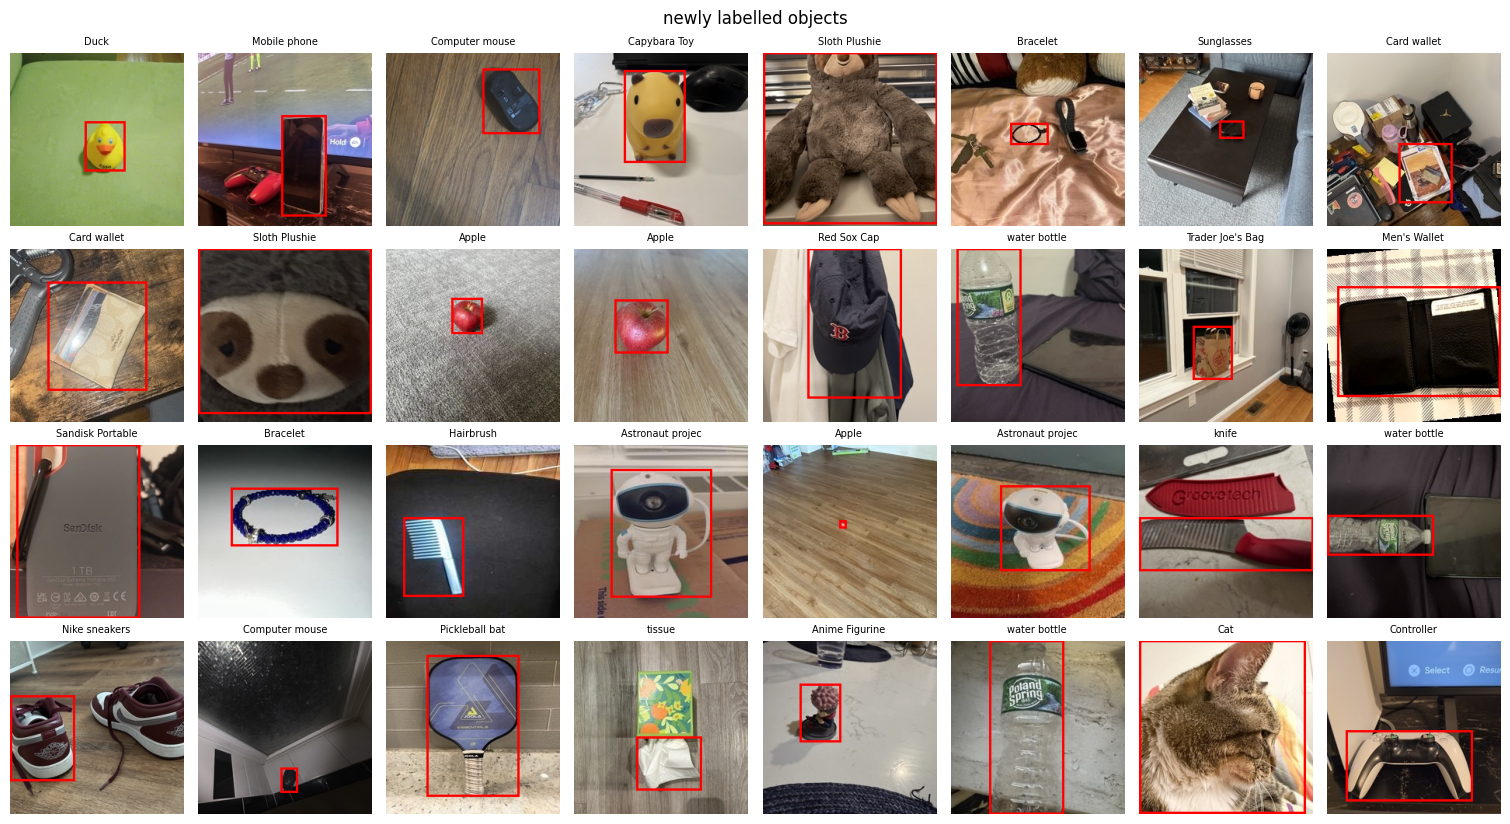

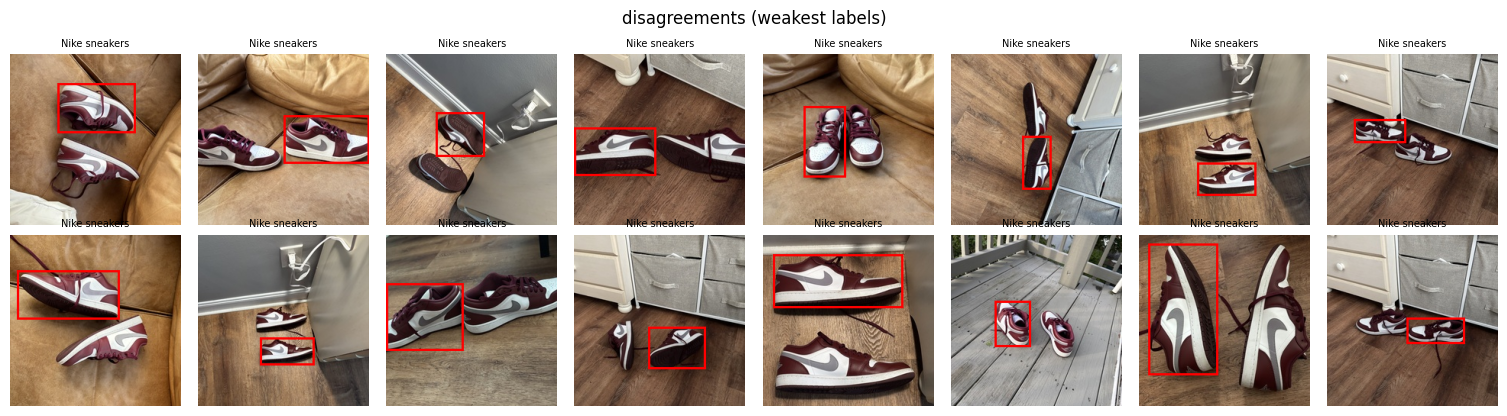

In [ ]:
def sheet(df, n=48, cols=8, title=""):
    df = df.head(n)
    rows = max(1, int(np.ceil(len(df) / cols)))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.9, rows * 2.1))
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    for ax, r in zip(np.atleast_1d(axes).ravel(), df.itertuples()):
        im = Image.open(DATA / r.filepath).convert("RGB")
        d = ImageDraw.Draw(im)
        d.rectangle([r.x1, r.y1, r.x2, r.y2], outline=(255, 0, 0), width=3)
        ax.imshow(im); ax.set_title(NAMES[r.label][:16], fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()

sheet(new.sample(min(32, len(new)), random_state=0), n=32, title="newly labelled objects")
sheet(new[new.status == "disagree"], n=16, title="disagreements (weakest labels)")

## Step 6: Build the grids over all 73 objects

Places 224x224 photos side by side in five layouts (2x2, 3x3, 4x4, 5x4, 5x5). All photos in a grid come from the same split and are all different. Each photo gets a random horizontal flip (with its box mirrored) and a small brightness change. A YOLO label file is written for every grid. 400 train, 80 val and 80 test grids, seed 73.


In [ ]:
TILE = 224
GRIDS = {"2x2": (2, 2), "3x3": (3, 3), "4x4": (4, 4), "5x4": (5, 4), "5x5": (5, 5)}
GRID_WEIGHTS = [0.15, 0.20, 0.25, 0.20, 0.20]
N_GRIDS = {"train": 400, "val": 80, "test": 80}
SEED = 73
GRID_DIR = Path("/content/grids73")

CLASS_IDS = sorted(used.label.unique())
cls_index = {l: i for i, l in enumerate(CLASS_IDS)}
shutil.rmtree(GRID_DIR, ignore_errors=True)
logs = []

def make_grids(used, split, n, seed, out_root=GRID_DIR):
    rng = random.Random(seed)
    pool = used[used.split == split].to_dict("records")
    img_dir = out_root / split / "images"; lab_dir = out_root / split / "labels"
    img_dir.mkdir(parents=True, exist_ok=True); lab_dir.mkdir(parents=True, exist_ok=True)
    sizes = list(GRIDS)
    for g in range(n):
        size = rng.choices(sizes, weights=GRID_WEIGHTS)[0]
        cols, rows = GRIDS[size]
        W, H = cols * TILE, rows * TILE
        canvas = Image.new("RGB", (W, H)); lines = []
        for k, r in enumerate(rng.sample(pool, cols * rows)):
            cx0, cy0 = (k % cols) * TILE, (k // cols) * TILE
            im = Image.open(DATA / r["filepath"]).convert("RGB")
            x1, y1, x2, y2 = r["x1"], r["y1"], r["x2"], r["y2"]
            if rng.random() < 0.5:
                im = ImageOps.mirror(im); x1, x2 = TILE - x2, TILE - x1
            im = ImageEnhance.Brightness(im).enhance(rng.uniform(0.85, 1.15))
            canvas.paste(im, (cx0, cy0))
            bx1, by1, bx2, by2 = x1 + cx0, y1 + cy0, x2 + cx0, y2 + cy0
            lines.append(f"{cls_index[r['label']]} {(bx1+bx2)/2/W:.6f} {(by1+by2)/2/H:.6f} "
                         f"{(bx2-bx1)/W:.6f} {(by2-by1)/H:.6f}")
        name = f"{split}_{g:04d}_{size}"
        canvas.save(img_dir / f"{name}.jpg", quality=92)
        (lab_dir / f"{name}.txt").write_text("\n".join(lines) + "\n")
        logs.append({"grid": name, "split": split, "size": size, "objects": cols * rows})

for sp, n in N_GRIDS.items():
    make_grids(used, sp, n, SEED + len(sp))
logs = pd.DataFrame(logs)
logs.to_csv(M2_DIR / "grid_log_73.csv", index=False)
print(logs.groupby(["split", "size"]).size().unstack(fill_value=0))
print("objects per split:", logs.groupby("split").objects.sum().to_dict(), "| classes:", len(CLASS_IDS))

size   2x2  3x3  4x4  5x4  5x5
split                         
test    11   22   17   14   16
train   62   70   97   92   79
val     11   18   19   12   20
objects per split: {'test': 1194, 'train': 6245, 'val': 1250} | classes: 73


In [ ]:
import yaml
DATA_YAML = GRID_DIR / "data73.yaml"
yaml.safe_dump({"path": str(GRID_DIR), "train": "train/images", "val": "val/images",
                "test": "test/images",
                "names": {i: n for i, n in enumerate(CLASS_IDS)}}, open(DATA_YAML, "w"))
print(DATA_YAML.read_text()[:300])

names:
  0: OBJ001
  1: OBJ002
  2: OBJ003
  3: OBJ004
  4: OBJ005
  5: OBJ006
  6: OBJ007
  7: OBJ008
  8: OBJ009
  9: OBJ010
  10: OBJ011
  11: OBJ012
  12: OBJ013
  13: OBJ014
  14: OBJ015
  15: OBJ016
  16: OBJ017
  17: OBJ018
  18: OBJ019
  19: OBJ020
  20: OBJ021
  21: OBJ022
  22: OBJ023
  23


## Step 7: Train

YOLOv8s from COCO weights with a new 73-class head: 1120 px (the size of the largest grid), batch 8, mosaic off (the grids are already multi-object images), seed 42, deterministic, AMP, checkpoints every 5 epochs.

**`EPOCHS` is the dial.** 80 is used here; 30 to 40 gets most of the way from pretrained weights if time is short.


In [ ]:
from ultralytics import YOLO

SEED = 42
IMG_SIZE = 1120
BATCH_SIZE = 8
EPOCHS = 80

PROJECT_DIR = M2_DIR / "runs"
RUN_NAME = "yolov8s_73cls_seed42"
RUN_DIR = PROJECT_DIR / RUN_NAME
LAST_CKPT = RUN_DIR / "weights" / "last.pt"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

if LAST_CKPT.exists():
    raise RuntimeError("An existing checkpoint was found. Use the resume cell below instead of starting over.")

model = YOLO("yolov8s.pt")
results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    mosaic=0.0,
    device=0,
    seed=SEED,
    deterministic=True,
    amp=True,
    patience=EPOCHS,
    workers=2,
    cache=False,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,
    save=True,
    save_period=5,
    plots=True,
    verbose=True,
)
print("Best model:", RUN_DIR / "weights" / "best.pt")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/grids73/data73.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1120, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov8s_73cls_seed42, nbs=64, nms=None, opset=None, optimize=

### Resume, if Colab disconnects
Run this instead of the training cell above.

In [ ]:
# from ultralytics import YOLO
# model = YOLO(str(LAST_CKPT))
# model.train(resume=True)

## Step 8: Evaluate on the test grids

In [ ]:
BEST_MODEL = RUN_DIR / "weights" / "best.pt"
assert BEST_MODEL.exists(), BEST_MODEL

best = YOLO(str(BEST_MODEL))
m = best.val(data=str(DATA_YAML), split="test", imgsz=IMG_SIZE, plots=True)
print(f"\nTEST  mAP@0.5 {m.box.map50:.3f} | mAP@0.5:0.95 {m.box.map:.3f} | "
      f"precision {m.box.mp:.3f} | recall {m.box.mr:.3f}")

per = pd.DataFrame({"id": [CLASS_IDS[i] for i in m.box.ap_class_index],
                    "object": [NAMES[CLASS_IDS[i]] for i in m.box.ap_class_index],
                    "AP50-95": m.box.maps[m.box.ap_class_index]}).sort_values("AP50-95")
per.to_csv(M2_DIR / "per_object_73.csv", index=False)
print("\nweakest 12:"); display(per.head(12).style.format({"AP50-95": "{:.3f}"}))
print("strongest 5:"); display(per.tail(5).style.format({"AP50-95": "{:.3f}"}))
shutil.copy(BEST_MODEL, M2_DIR / "best_detector_73.pt")
print("copied to", M2_DIR / "best_detector_73.pt")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 48.7±21.8 MB/s, size: 198.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/grids73/test/labels... 80 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 533.3it/s 0.2s
val: New cache created: /content/grids73/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.4s/it 6.9s
                   all         80       1194      0.919      0.891      0.924      0.866
                OBJ001         15         17      0.961          1      0.995      0.988
                OBJ002         18         21          1      0.976      0.995      0.978
                OBJ003  

,id,object,AP50-95
67,OBJ068,Neck Pillow,0.206
12,OBJ013,Mobile phone,0.456
61,OBJ062,Headphones,0.522
13,OBJ014,Sunglasses,0.539
33,OBJ034,Table Tennis Racket,0.556
41,OBJ042,Mouth guard case,0.611
49,OBJ050,Hairbrush,0.684
31,OBJ032,Sound Card,0.687
64,OBJ065,Analog watch,0.705
9,OBJ010,Nike sneakers,0.706


strongest 5:


,id,object,AP50-95
72,OBJ073,Bowl,0.990
11,OBJ012,Computer Keyboard,0.995
29,OBJ030,Tennis racket,0.995
28,OBJ029,Orange,0.995
39,OBJ040,Clutcher,0.995


copied to /content/drive/MyDrive/IE7615_detection/best_detector_73.pt


## Step 9: One detection per cell

Each 224 px cell holds one object, so only the strongest detection per cell is kept. Scores the raw output and the filtered output on all test grids (correct = right Object ID and IoU of at least 0.5).


In [ ]:
import glob

def predict_boxes(img_path, conf=0.25):
    r = best.predict(str(img_path), imgsz=IMG_SIZE, conf=conf, verbose=False)[0]
    return [[*b.xyxy[0].tolist(), float(b.conf), int(b.cls)] for b in r.boxes]

def one_per_cell(dets, tile=TILE):
    keep = {}
    for d in dets:
        cell = (int((d[1] + d[3]) / 2 // tile), int((d[0] + d[2]) / 2 // tile))
        if cell not in keep or d[4] > keep[cell][4]:
            keep[cell] = d
    return list(keep.values())

def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0.0

stats = {"raw": [0, 0, 0], "one_per_cell": [0, 0, 0]}
for ip in tqdm(sorted(glob.glob(str(GRID_DIR / "test" / "images" / "*.jpg"))), desc="scoring"):
    lp = GRID_DIR / "test" / "labels" / (Path(ip).stem + ".txt")
    W, H = Image.open(ip).size
    gt = []
    for line in lp.read_text().splitlines():
        c, cx, cy, w, h = line.split(); c = int(c)
        cx, cy, w, h = float(cx)*W, float(cy)*H, float(w)*W, float(h)*H
        gt.append([cx-w/2, cy-h/2, cx+w/2, cy+h/2, c])
    raw = predict_boxes(ip)
    for key, dets in (("raw", raw), ("one_per_cell", one_per_cell(raw))):
        matched = set(); tp = fp = 0
        for d in sorted(dets, key=lambda x: -x[4]):
            hit = None
            for gi, g in enumerate(gt):
                if gi in matched or g[4] != d[5]:
                    continue
                if box_iou(d[:4], g[:4]) >= 0.5:
                    hit = gi; break
            if hit is None: fp += 1
            else: tp += 1; matched.add(hit)
        stats[key][0] += tp; stats[key][1] += fp; stats[key][2] += len(gt) - len(matched)

for key, (tp, fp, fn) in stats.items():
    p = tp/(tp+fp) if tp+fp else 0
    r = tp/(tp+fn) if tp+fn else 0
    f1 = 2*p*r/(p+r) if p+r else 0
    print(f"{key:<13} P {p:.3f}  R {r:.3f}  F1 {f1:.3f}   (tp {tp}, fp {fp}, fn {fn})")

scoring:   0%|          | 0/80 [00:00<?, ?it/s]

raw           P 0.934  R 0.891  F1 0.912   (tp 1064, fp 75, fn 130)
one_per_cell  P 0.960  R 0.885  F1 0.921   (tp 1057, fp 44, fn 137)


## Summary

- All 73 objects in the shared sheet: 38 from Section 01 and 35 from Section 03.
- 6,006 labelled photos (3,048 Section 01 and 2,958 Section 03), fused from YOLO-World and Grounding DINO boxes.
- 560 grids (400 / 80 / 80), seed 73.
- YOLOv8s, 73 classes, 80 epochs. Test: mAP@0.5 0.924, mAP@0.5:0.95 0.866, precision 0.919, recall 0.891.
- One detection per cell: precision 0.960, recall 0.885, F1 0.921.


## Step 10: Detection function

`detect_objects` takes any grid image (a file path, PIL image or numpy array) and returns every object the model finds: the object ID, the object name, the confidence, the bounding box in pixels (`x1, y1, x2, y2`) and the grid cell (row and column). Only the most confident detection in each cell is kept (Step 9); `one_per_cell=False` returns the raw output. Results are sorted in reading order.


In [ ]:
import json

def detect_objects(image, conf=0.25, tile=TILE, one_per_cell=True, show=False):
    """Detect objects in a grid image.

    image: file path, PIL image or numpy array
    returns: list of dicts with object_id, name, confidence, box [x1, y1, x2, y2] in pixels, and grid row/col
    """
    if isinstance(image, (str, Path)):
        image = Image.open(image).convert("RGB")
    res = best.predict(image, imgsz=IMG_SIZE, conf=conf, verbose=False)[0]
    out = []
    for c, s, b in zip(res.boxes.cls.tolist(), res.boxes.conf.tolist(), res.boxes.xyxy.tolist()):
        oid = best.names[int(c)]
        x1, y1, x2, y2 = [round(v, 1) for v in b]
        out.append({"object_id": oid, "name": NAMES.get(oid, ""), "confidence": round(s, 3),
                    "box": [x1, y1, x2, y2],
                    "row": int(((y1 + y2) / 2) // tile), "col": int(((x1 + x2) / 2) // tile)})
    if one_per_cell:
        keep = {}
        for d in out:
            k = (d["row"], d["col"])
            if k not in keep or d["confidence"] > keep[k]["confidence"]:
                keep[k] = d
        out = list(keep.values())
    out.sort(key=lambda d: (d["row"], d["col"]))
    if show:
        img = image if isinstance(image, Image.Image) else Image.fromarray(image)
        img = img.copy(); dr = ImageDraw.Draw(img)
        for d in out:
            dr.rectangle(d["box"], outline=(255, 60, 60), width=3)
            dr.text((d["box"][0] + 3, d["box"][1] + 2), f'{d["object_id"]} {d["confidence"]:.2f}', fill=(255, 60, 60))
        plt.figure(figsize=(10, 10)); plt.imshow(img); plt.axis("off")
        plt.title(f"detect_objects: {len(out)} objects found"); plt.show()
    return out

# example:
# found = detect_objects(sorted((GRID_DIR / "test" / "images").glob("*.jpg"))[0], show=True)
# print(json.dumps(found, indent=2))
